# コードの目的
ノード数に対する最適なバックオフ時間を見つける。ただし、バックオフ時間は2**N[TU]であるため、厳密な最適なバックオフ時間ではありません。

# 1.必要なライブラリ

In [3]:
from pathlib import Path
import re
import pandas as pd
import yaml
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

## 2. PDFの出力先設定

ログの入力先と、生成するPDFの保存先を設定します。必要に応じてこのセルだけ編集してください。

In [6]:
LOG_DIR = Path("tsv/optimal_backoff_20260428")

# PDF出力先
OUTPUT_DIR = Path("img/analysis")
COLLISION_RATE_PDF = OUTPUT_DIR / "collision_rate_comparison_optimal_backoff.pdf"
THROUGHPUT_PER_NODE_BPS_PDF = OUTPUT_DIR / "throughput_per_node_bps_comparison_optimal_backoff.pdf"

# 3. 解析コード
各ノード数でTagあたりのスループットが最大となるバックオフ時間をプロットするコードです。必要に応じて編集してください。

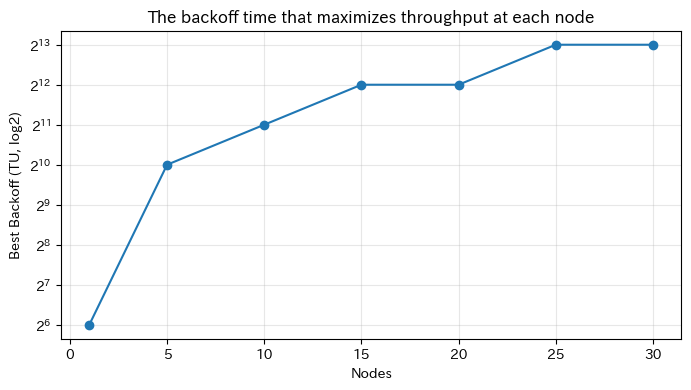

Best backoff per node (nodes, backoff, throughput_per_tag_bps):
 nodes  backoff  throughput_per_tag_bps
     1       64            15172.755600
     5     1024             1301.265307
    10     2048              589.139608
    15     4096              377.825798
    20     4096              280.945356
    25     8192              211.585502
    30     8192              181.979308


In [8]:
# ノード／バックオフの期待値（必要に応じて編集）
nodes = [1, 5, 10, 15, 20, 25, 30]
backoffs = [64,128,256,512,1024,2048,4096,8192,16384]


def load_events(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, sep='	')
    df['time_tu'] = pd.to_numeric(df['time_tu'], errors='coerce')
    df['round'] = pd.to_numeric(df['round'], errors='coerce').astype('Int64')
    df['event'] = df['event'].astype(str)
    df['result'] = df['result'].astype(str)
    return df

def load_config(path: Path) -> dict:
    if not path.exists():
        return {}
    with path.open('r', encoding='utf-8') as f:
        return yaml.safe_load(f)

rows = []
LOG_DIR = Path(LOG_DIR)
if not LOG_DIR.exists():
    raise FileNotFoundError(f'LOG_DIR not found: {LOG_DIR}')

for n in nodes:
    node_dir = LOG_DIR / f'node_{n}'
    if not node_dir.exists():
        # skip missing node dirs but continue
        print('missing', node_dir)
        continue

    # try to load config from node dir, fallback to parent
    cfg = load_config(node_dir / 'config.yaml') or load_config(LOG_DIR / 'config.yaml')
    data_bits = float(cfg.get('data_bits', cfg.get('data_bits', 128)))
    tu_sec = float(cfg.get('tu', cfg.get('tu', 0.0001)))

    # list candidate files in node_dir matching *_<backoff>.tsv (events/evens tolerant)
    for path in sorted(node_dir.glob('*_*tsv')):
        m = re.search(r'_(\d+)\.tsv$', path.name)
        if not m:
            continue
        b = int(m.group(1))
        if b not in backoffs:
            continue

        events = load_events(path)
        if events.empty:
            continue

        # success mask: PIM uses 'rx_success'
        success_mask = events['event'] == 'rx_success'
        successes = int(success_mask.sum())

        # average per-round timing like summarize_protocol
        round_last = events.groupby('round')['time_tu'].max()
        num_rounds = int(round_last.shape[0]) if round_last.shape[0] > 0 else 0
        avg_round_tu = float(round_last.mean()) if num_rounds > 0 else 0.0
        avg_round_sec = avg_round_tu * tu_sec if avg_round_tu > 0 else 0.0
        avg_successes_per_round = (successes / num_rounds) if num_rounds > 0 else 0.0

        throughput_bps = (avg_successes_per_round * data_bits / avg_round_sec) if avg_round_sec > 0 else 0.0
        throughput_per_tag_bps = (throughput_bps / n) if n > 0 else 0.0

        rows.append({'nodes': n, 'backoff': b, 'throughput_per_tag_bps': throughput_per_tag_bps})

# 結果をDataFrame化
df = pd.DataFrame(rows)
if df.empty:
    raise RuntimeError('No event files processed; check LOG_DIR and naming patterns')

# 各ノードで最大スループットとなるバックオフを選定
best = df.loc[df.groupby('nodes')['throughput_per_tag_bps'].idxmax()].sort_values('nodes')

# プロット: ノード対最適バックオフ（対数スケール表示）
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(best['nodes'], best['backoff'], marker='o')
ax.set_xscale('linear')
ax.set_yscale('log', base=2)
ax.set_xlabel('Nodes')
ax.set_ylabel('Best Backoff (TU, log2)')
ax.set_title('The backoff time that maximizes throughput at each node')
ax.grid(alpha=0.3)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with PdfPages(THROUGHPUT_PER_NODE_BPS_PDF) as pdf:
    pdf.savefig(fig, bbox_inches='tight')
plt.show()

# 表示: best と元データ（任意）
print('Best backoff per node (nodes, backoff, throughput_per_tag_bps):')
print(best[['nodes','backoff','throughput_per_tag_bps']].to_string(index=False))
